# CirKreety Integrated Power, Oscillator & MOSFET Workbench

**One connected circuit · one CircuitIR · one end-to-end CirKreety/CirChecker analysis**

This compact notebook imports one SPICE-compatible circuit source, validates its unified `CircuitIR`, runs every analysis supported for this nonlinear switching circuit, measures the signals with `SignalAnalyzer`, plots the waveforms, and writes structural plus numerical JSON reports.

The integrated chain contains five connected functional stages:

1. Centre-tapped full-wave rectifier
2. Reservoir low-pass filter
3. Zener shunt voltage regulator
4. Hysteretic RC relaxation oscillator
5. Oscillator-coupled NMOS common-source amplifier

## Full connected circuit schematic

![Full integrated circuit schematic](../examples/images/full_integrated_circuit_schematic.png)

## Circuit overview

![Integrated circuit overview](../examples/images/integrated_circuit_overview.png)

## Input circuit diagrams

The following drawings document the connections represented by the executable `.cir` input. The `.cir` netlist is the authoritative electrical connectivity and model input; these PNG/SVG images are companion schematic illustrations, not image files parsed by CirKreety.

![Centre-tapped rectifier and filter](../examples/images/stage1_ct_rectifier_lowpass.png)

![Zener shunt regulator](../examples/images/stage2_zener_shunt_regulator.png)

![Relaxation oscillator](../examples/images/stage3_relaxation_oscillator.png)

![NMOS common-source amplifier](../examples/images/stage4_nmos_common_source_amplifier.png)

![Inter-stage connectivity map](../examples/images/integrated_circuit_connectivity.png)

## Modeling boundary

- The two sinusoidal half-winding voltage sources model an **ideal centre-tapped transformer secondary**; magnetic coupling, leakage inductance, winding capacitance and core losses are not modeled.
- The Zener uses the package's simplified reverse-breakdown diode model, not a manufacturer-validated device model.
- The oscillator uses CirKreety's voltage-controlled hysteretic switch primitives. It is an RC relaxation oscillator demonstration, **not a 555 timer IC model**.
- The MOSFET uses the package's educational Level-1 compact model, not a BSIM/vendor model; thermal behavior and detailed parasitics are omitted.
- DC operating point, DC sweep, local small-signal AC sweep and nonlinear transient are applicable here. Linear-only derived analyses (frequency analysis, transfer function, state space) are expected to report `not_applicable` for this nonlinear switching topology.

**No external circuit simulator or third-party EDA package is called by this notebook.** The notebook uses the public CirKreety/CirChecker API plus Python's standard library. NumPy, SciPy and Matplotlib are internal dependencies of CirKreety itself.

In [1]:
from pathlib import Path
import json

from circhecker import CircuitReviewer, SchematicExtractor, SignalAnalyzer

# Find the repository root whether Jupyter starts here or inside notebooks/.
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "circhecker").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "circhecker").is_dir():
    raise FileNotFoundError("Run this notebook from inside the CirKreety-EDA project directory.")

SCHEMATIC_PATH = ROOT / "examples" / "schematics" / "integrated_ct_supply_oscillator_cs_mosfet.cir"
REPORT_DIR = ROOT / "reports" / "integrated_workbench"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

IR_JSON_PATH = REPORT_DIR / "integrated_circuit_ir.json"
ANALYSIS_JSON_PATH = REPORT_DIR / "integrated_circuit_analysis.json"
SIGNAL_JSON_PATH = REPORT_DIR / "integrated_signal_metrics.json"
PLOT_PATH = REPORT_DIR / "integrated_workbench.png"

print(f"Input circuit     : {SCHEMATIC_PATH.relative_to(ROOT)}")
print(f"Report directory : {REPORT_DIR.relative_to(ROOT)}")
assert SCHEMATIC_PATH.is_file(), f"Missing circuit input: {SCHEMATIC_PATH}"

Input circuit     : examples/schematics/integrated_ct_supply_oscillator_cs_mosfet.cir
Report directory : reports/integrated_workbench


## 1. Import the circuit and create the unified CircuitIR

`SchematicExtractor` reads the single source file. The extracted representation is then validated and exported as a schema-checked structural JSON document before numerical execution.

In [2]:
extractor = SchematicExtractor()
circuit_ir = extractor.extract(SCHEMATIC_PATH)
validation = extractor.validate(circuit_ir)
extractor.export_json(circuit_ir, IR_JSON_PATH)

component_refs = [component.get("reference", "?") for component in circuit_ir.components]
node_names = [node.get("name", str(node.get("id"))) for node in circuit_ir.nodes if int(node.get("id", 0)) != 0]

print("Circuit title      :", circuit_ir.metadata.get("title"))
print("Components         :", len(circuit_ir.components))
print("Non-ground nodes   :", len(node_names))
print("Nodes              :", ", ".join(node_names))
print("Structural status  :", validation.get("status"))
print("Structural errors  :", len(validation.get("errors", [])))
print("Structural warnings:", len(validation.get("warnings", [])))
print("CircuitIR JSON     :", IR_JSON_PATH.relative_to(ROOT))
print("Component refs     :", ", ".join(component_refs))

assert validation.get("status") == "success", validation
assert not validation.get("errors"), validation.get("errors")

Circuit title      : Integrated centre-tapped supply, shunt regulator, relaxation oscillator and NMOS common-source amplifier
Components         : 28
Non-ground nodes   : 14
Nodes              : sec_a, sec_b, rect_a, rect_b, rect_raw, vreg, osc_cap, osc_out, drive, gate, drain, source, amp_out, ac_test
Structural status  : success
Structural errors  : 0
Structural warnings: 0
CircuitIR JSON     : reports/integrated_workbench/integrated_circuit_ir.json
Component refs     : VSEC_A, VSEC_B, RSA, RSB, D1, D2, Cbulk, Rbleed, Rseries, DZ, Rload, Creg, Rcharge, Cosc, Sdis, Rosc_pullup, Sout, Rdrive, Cdrive, Rgate_top, Rgate_bottom, RD, RS, M1, Cout, Rout, VTEST, Ctest


## 2. Run CirKreety/CirChecker's supported analyses

The same `CircuitIR` is passed to `CircuitReviewer`; there is no second parser or alternate solver path. `analyses="all"` asks CirKreety to check its analysis registry and marks analyses unsupported for this circuit as `not_applicable` rather than pretending they ran.

In [3]:
reviewer = CircuitReviewer(output_dir=REPORT_DIR, plot=False)
result = reviewer.process_ir(circuit_ir, analyses="all", save_json=False, plot=False)
summary = result.summary()

print("Overall status :", summary["status"])
print("Backend        :", summary["backend"])
print("KCL check      :", summary["kcl_check"])
print("Components     :", summary["component_count"])
print("Nodes          :", summary["node_count"])
print("Warnings       :", summary["warnings"])
print("Errors         :", summary["errors"])
print("\nAnalysis status")
for name, status in summary["analysis_status"].items():
    print(f"  {name:24s} {status}")

assert result.status == "success", {"summary": summary, "errors": result.errors}
for required in ("dc_operating_point", "dc_sweep", "ac_sweep", "transient"):
    assert summary["analysis_status"].get(required) == "success", summary["analysis_status"]

kcl = result.engineering_checks.get("kcl", {})
print(f"\nMaximum KCL residual: {kcl.get('max_residual_A', float('nan')):.3e} A")

Overall status : success
Backend        : nonlinear_analog
KCL check      : passed
Components     : 28
Nodes          : 14
Warnings       : 0
Errors         : 0

Analysis status
  dc_operating_point       success
  dc_sweep                 success
  ac_sweep                 success
  transient                success
  frequency_analysis       not_applicable
  transfer_function        not_applicable
  state_space              not_applicable

Maximum KCL residual: 1.697e-11 A


## 3. Numerical results and signal measurements

The DC values below come from the nonlinear operating-point solution. Time-domain metrics are calculated from the final 40 ms of the 60 ms transient record to avoid reporting the initial startup interval as steady-state behavior. `SignalAnalyzer` is used for RMS, AC RMS, peak-to-peak ripple, and zero-crossing frequency; the AC sweep is measured separately as a frequency response.

In [4]:
analyzer = SignalAnalyzer()
transient = result.analysis_results["transient"]["data"]
time_s = list(transient["time_s"])
node_values = transient["node_voltages_V"]
node_id_by_name = {str(node["name"]): int(node["id"]) for node in circuit_ir.nodes}

settled_indices = [i for i, t in enumerate(time_s) if t >= 0.020]
settled_time = [time_s[i] for i in settled_indices]

def trace(node_name):
    node_id = node_id_by_name[node_name]
    values = node_values.get(node_id, node_values.get(str(node_id)))
    if values is None:
        raise KeyError(f"Transient solver did not return node {node_name!r}.")
    return list(values)

signal_reports = {}
for node_name in ("rect_raw", "vreg", "osc_cap", "osc_out", "gate", "amp_out"):
    values = trace(node_name)
    signal_reports[node_name] = analyzer.analyze(
        settled_time,
        [values[i] for i in settled_indices],
        name=f"V({node_name})",
        unit="V",
        window="hann",
        expected_max_frequency_hz=10_000,
    )

# DC operating point, component operating data and sweep endpoints.
op_nodes = result.numerical_metrics["node_voltages_V"]
components = result.numerical_metrics["component_electrical_metrics"]["components"]
node_op = {name: float(op_nodes[name]) for name in ("rect_raw", "vreg", "osc_cap", "osc_out", "gate", "drain", "source", "amp_out")}
mos = components["M1"]
zener = components["DZ"]

sweep = result.analysis_results["dc_sweep"]["data"]
source_sweep = [float(v) for v in sweep["source_V"]]
regulator_sweep = [float(v) for v in sweep["output_V"]]

ac = result.analysis_results["ac_sweep"]["data"]
frequency = [float(v) for v in ac["frequency_Hz"]]
response = ac["response"]
ac_summary = analyzer.analyze_ac(frequency, response, name="V(amp_out)/V(ac_test)", unit="V/V")
near_1k = min(range(len(frequency)), key=lambda i: abs(frequency[i] - 1000.0))
ac_at_1k = {
    "frequency_Hz": frequency[near_1k],
    "gain_V_per_V": abs(response[near_1k]),
    "magnitude_dB": float(ac["magnitude_dB"][near_1k]),
    "phase_deg": float(ac["phase_deg"][near_1k]),
}

def compact_signal_result(report):
    spectrum = report.spectrum or {}
    harmonics = report.harmonics or {}
    sampling_keys = ("sample_rate_hz", "nyquist_frequency_hz", "is_uniform_sampling",
                     "true_frequency_resolution_hz", "fft_bin_spacing_hz", "window",
                     "spectral_leakage_risk", "aliasing")
    return {
        "metrics": report.metrics,
        "sampling": {key: report.sampling.get(key) for key in sampling_keys if key in report.sampling},
        "spectrum_summary": {
            key: spectrum.get(key)
            for key in ("dominant_frequency_hz", "dominant_amplitude", "fundamental_frequency_hz")
            if key in spectrum
        },
        "thd_percent": harmonics.get("thd_percent"),
    }

metrics = {
    "circuit": summary,
    "analysis_status": summary["analysis_status"],
    "dc_operating_point_V": node_op,
    "zener_DZ": {
        "voltage_V_anode_to_cathode": float(zener["voltage_V"]),
        "current_A_anode_to_cathode": float(zener["current_A"]),
        "power_W": float(zener["power_W"]),
        "operating_state": zener.get("operating_state"),
    },
    "mosfet_M1": {
        "drain_current_A": float(mos["current_A"]),
        "VGS_V": float(mos["VGS_V"]),
        "VDS_V": float(mos["VDS_V"]),
        "transconductance_approx_S": float(mos["transconductance_approx_S"]),
        "operating_region": mos.get("operating_region"),
    },
    "settled_transient_window_s": {"start": 0.020, "end": float(time_s[-1]), "samples": len(settled_indices)},
    "signal_metrics": {name: compact_signal_result(report) for name, report in signal_reports.items()},
    "mosfet_amplifier_transient_rms_ratio_V_per_V": (
        signal_reports["amp_out"].metrics["ac_rms"] / signal_reports["gate"].metrics["ac_rms"]
    ),
    "dc_line_sweep": {
        "swept_source": "VSEC_A DC value (one half-secondary source)",
        "input_min_V": min(source_sweep),
        "input_max_V": max(source_sweep),
        "vreg_min_V": min(regulator_sweep),
        "vreg_max_V": max(regulator_sweep),
    },
    "small_signal_ac_near_1kHz": ac_at_1k,
    "small_signal_ac_response_summary": ac_summary,
    "kcl": result.engineering_checks.get("kcl", {}),
}

print("DC operating point (V)")
for name, value in node_op.items():
    print(f"  {name:10s} {value:10.5f}")
print("\nSelected device operating values")
print(f"  DZ current magnitude : {abs(zener['current_A'])*1e3:.3f} mA")
print(f"  M1 drain current     : {mos['current_A']*1e3:.3f} mA")
print(f"  M1 VGS / VDS         : {mos['VGS_V']:.3f} V / {mos['VDS_V']:.3f} V ({mos['operating_region']})")
print("\nSettled transient measurements (20–60 ms)")
for name in ("rect_raw", "vreg", "osc_cap", "osc_out", "gate", "amp_out"):
    m = signal_reports[name].metrics
    print(f"  {name:10s} mean={m['mean']:.5f} V  AC RMS={m['ac_rms']:.5f} V  p-p={m['peak_to_peak']:.5f} V  fzc={m['zero_crossing_frequency_hz']}")
print(f"  MOSFET stage transient AC RMS ratio: {metrics['mosfet_amplifier_transient_rms_ratio_V_per_V']:.3f} V/V")
print("\nDC regulator sweep: VREG = {:.3f}–{:.3f} V as VSEC_A sweeps {:.1f}–{:.1f} V".format(min(regulator_sweep), max(regulator_sweep), min(source_sweep), max(source_sweep)))
print("AC small-signal near 1 kHz: {:.1f} Hz, {:.3f} V/V, {:.2f} dB, {:.1f}°".format(ac_at_1k["frequency_Hz"], ac_at_1k["gain_V_per_V"], ac_at_1k["magnitude_dB"], ac_at_1k["phase_deg"]))

DC operating point (V)
  rect_raw     15.53214
  vreg          5.17124
  osc_cap       3.88815
  osc_out       5.12004
  gate          2.58562
  drain         2.69603
  source        0.52879
  amp_out       0.00000

Selected device operating values
  DZ current magnitude : 8.905 mA
  M1 drain current     : 1.125 mA
  M1 VGS / VDS         : 2.057 V / 2.167 V (saturation)

Settled transient measurements (20–60 ms)
  rect_raw   mean=15.29958 V  AC RMS=0.06463 V  p-p=0.22297 V  fzc=None
  vreg       mean=5.16821 V  AC RMS=0.00083 V  p-p=0.00341 V  fzc=241.06056725392364
  osc_cap    mean=2.78865 V  AC RMS=0.23689 V  p-p=0.79961 V  fzc=282.5194103360659
  osc_out    mean=2.85192 V  AC RMS=2.50836 V  p-p=5.05472 V  fzc=282.51849784662454
  gate       mean=2.42081 V  AC RMS=0.01605 V  p-p=0.07277 V  fzc=292.92447920507993
  amp_out    mean=0.24922 V  AC RMS=0.05110 V  p-p=0.21997 V  fzc=259.93225264619446
  MOSFET stage transient AC RMS ratio: 3.185 V/V

DC regulator sweep: VREG = 3.987–5.204

## 4. CirKreety signal plots

This six-panel workbench plot is generated by `CircuitResult.plot_workbench` from the same analysis object: rectifier/filter signals, regulator ripple, oscillator waveforms, MOSFET input/output AC components, regulator DC line sweep, and the small-signal AC response.

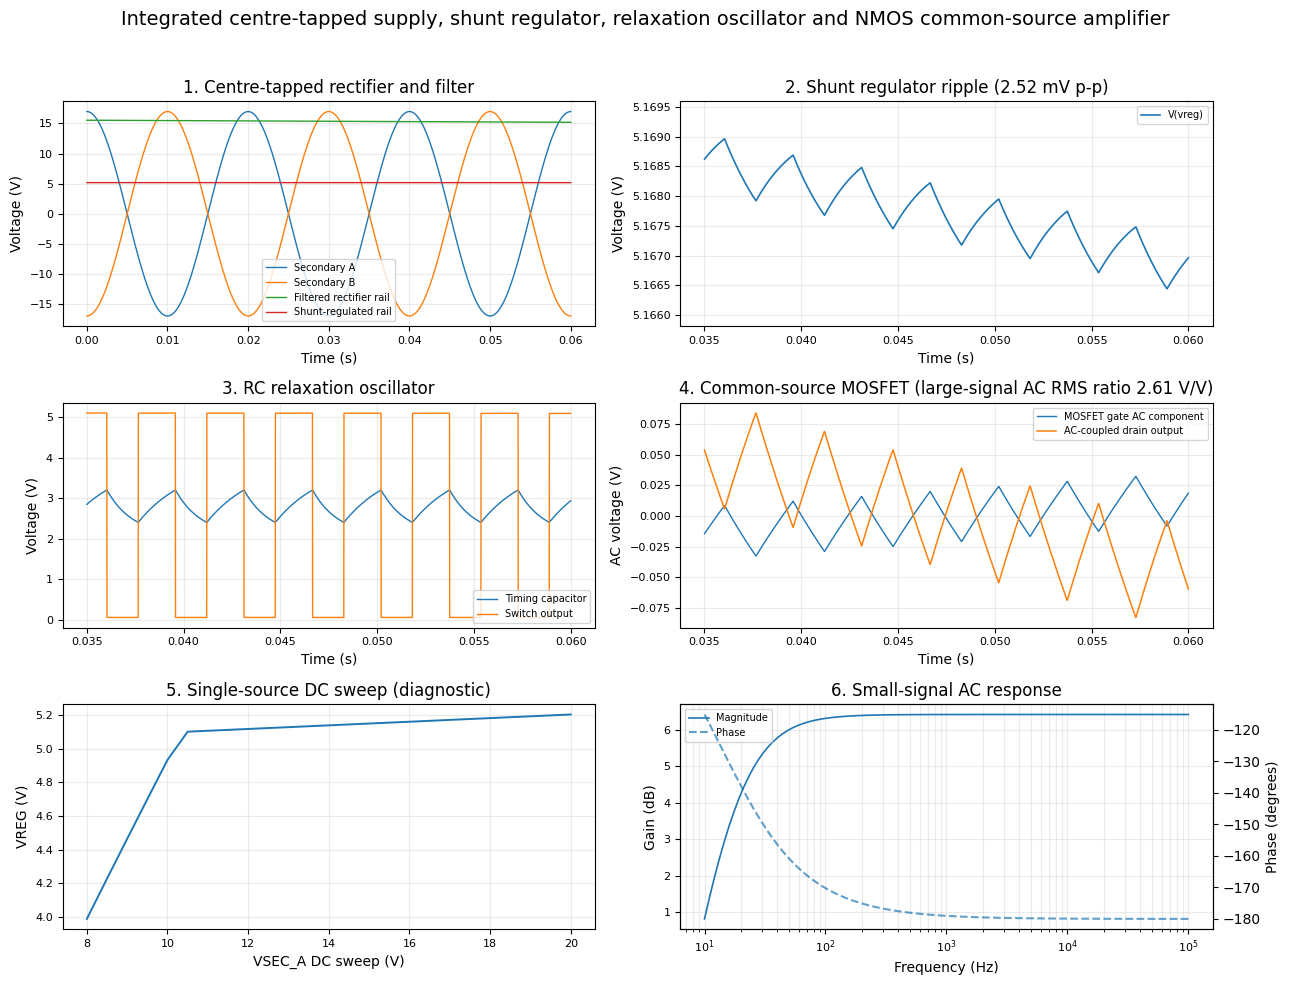

Workbench plot saved: reports/integrated_workbench/integrated_workbench.png


In [5]:
figure = result.plot_workbench(show=True, path=PLOT_PATH, window_s=0.025)
print("Workbench plot saved:", PLOT_PATH.relative_to(ROOT))

## 5. Export machine-readable JSON reports

Three outputs are written:

- `integrated_circuit_ir.json` — schema-checked extracted CircuitIR (components, pins, nodes, branches, models and source metadata).
- `integrated_circuit_analysis.json` — complete CirKreety/CirChecker execution, analysis results, numerical metrics, engineering checks and artifact references.
- `integrated_signal_metrics.json` — focused numerical measurements for each plotted node plus AC and DC sweep summaries.

In [6]:
result.artifacts.update({
    "input_netlist": str(SCHEMATIC_PATH.relative_to(ROOT)),
    "circuit_ir_json": str(IR_JSON_PATH.relative_to(ROOT)),
    "signal_metrics_json": str(SIGNAL_JSON_PATH.relative_to(ROOT)),
    "workbench_plot": str(PLOT_PATH.relative_to(ROOT)),
    "schematic_overview": "examples/images/integrated_circuit_overview.png",
    "schematic_stage_images": [
        "examples/images/stage1_ct_rectifier_lowpass.png",
        "examples/images/stage2_zener_shunt_regulator.png",
        "examples/images/stage3_relaxation_oscillator.png",
        "examples/images/stage4_nmos_common_source_amplifier.png",
        "examples/images/integrated_circuit_connectivity.png",
    ],
})

with SIGNAL_JSON_PATH.open("w", encoding="utf-8") as handle:
    json.dump(metrics, handle, indent=2, ensure_ascii=False, allow_nan=False)
    handle.write("\n")

result.to_json(ANALYSIS_JSON_PATH)

for path in (IR_JSON_PATH, ANALYSIS_JSON_PATH, SIGNAL_JSON_PATH, PLOT_PATH):
    print(f"{path.relative_to(ROOT)}  |  {path.stat().st_size:,} bytes")

# Re-read both output JSON files to confirm that they are valid JSON.
json.loads(IR_JSON_PATH.read_text(encoding="utf-8"))
json.loads(ANALYSIS_JSON_PATH.read_text(encoding="utf-8"))
json.loads(SIGNAL_JSON_PATH.read_text(encoding="utf-8"))
print("JSON validation: all three reports parsed successfully.")

reports/integrated_workbench/integrated_circuit_ir.json  |  65,874 bytes
reports/integrated_workbench/integrated_circuit_analysis.json  |  3,112,640 bytes
reports/integrated_workbench/integrated_signal_metrics.json  |  31,997 bytes
reports/integrated_workbench/integrated_workbench.png  |  383,111 bytes
JSON validation: all three reports parsed successfully.


## Final engineering interpretation

| Section | What the run demonstrates |
|---|---|
| Rectifier + filter | Full-wave rectification and the ripple reduction from the 2200 µF reservoir capacitor |
| Shunt regulator | Zener clamp behavior and residual ripple on the regulated rail |
| Relaxation oscillator | Timing-capacitor ramp and hysteretic output switching |
| NMOS amplifier | DC bias point, gate/drain/source values, transient AC-coupled response and local AC response |
| CirKreety pipeline | Single-source import, CircuitIR extraction, structural validation, nonlinear analysis, signal measurement, plotting and JSON export |

### Read the reported gains correctly

The transient AC-RMS ratio compares the AC components of the oscillator-driven gate and AC-coupled drain output over the selected time window. It is a **large-signal waveform ratio**, not the same quantity as the local small-signal AC gain. The AC sweep uses the dedicated 1 V small-signal test port coupled into the gate and is linearized about the computed DC operating point.

### Model and design cautions

This is a compact, integrated software demonstration—not a validated production power supply or amplifier design. The transformer, Zener, hysteretic switches and MOSFET all use simplified educational representations. Check component ratings, thermal dissipation, startup behavior, ripple current, stability, transient response and datasheet models before physical construction. The notebook deliberately reports solver scope and `not_applicable` analyses instead of claiming capabilities the current engine does not provide.